In [1]:
from pymetropsis.paths import RAW_DIR, DERIVATIVES_DIR, FIG_DIR, TABLE_DIR, ensure_dir
import os

# check if current working directory is project root
def eval_at_project_root():
    if os.getcwd().endswith("civibe_psychophysics"):
        print("Current working directory is project root.")
    elif os.getcwd().endswith("notebooks"):
        os.chdir("..")
        print("Changed working directory to project root.")
    else:
        raise Exception("Current working directory is not project root or notebooks directory. Please change to project root.")


In [2]:
from pymetropsis.preprocess import clean_metropsis
import pandas as pd

clean_metropsis.get_data(
    data_filepath=RAW_DIR / "group/metropsis/dc_civibe/dc_civibe_TCS-2e.xls",
    meta_filepath=RAW_DIR / "group/metropsis/dc_civibe/dc_civibe_TCS-2e_blocks.xls",
    output_filepath=RAW_DIR / "clean_metropsis_dc.csv",
    standardized_start_datetime=pd.to_datetime("2024-01-01 08:00"),
    block_duration=pd.to_timedelta("1:15:00"),
)


/Users/sje30/proj/2020/codecheckers/2026/HeinrichsEtAl_JVis_2026/notebooks
Manually added column 'Block' exists.
Processed file saved in: /Users/sje30/proj/2020/codecheckers/2026/HeinrichsEtAl_JVis_2026/data/raw/clean_metropsis_dc.csv


In [3]:
from pymetropsis.plotting import plot_metropsis_group
import pandas as pd

from pymetropsis.postcontrol import plot_diurnal_control

data = pd.read_csv(RAW_DIR / "clean_metropsis_dc.csv")
data = data.loc[(data["participant_id"].notna())]
data["session"] = "DC"
# Create new column for context, C for constraint pupil, F for free viewing
data["context"] = "F"
# Set context to C for odd block numbers
data.loc[data["block"] % 2 == 1, "context"] = "C"
data["session_context"] = (data["session"] + "_" + data["context"]).str.lower()
print(data)



     Unnamed: 0  participant_id             datetime    condition  freq  \
0             0             113  2025-08-07 08:03:19   achromatic     2   
1             1             113  2025-08-07 08:03:19   achromatic     8   
2             2             113  2025-08-07 08:06:11  blue-yellow     2   
3             3             113  2025-08-07 08:06:11  blue-yellow     8   
4             4             113  2025-08-07 08:09:56    red-green     2   
..          ...             ...                  ...          ...   ...   
357         357             202  2025-08-19 19:31:53   achromatic     8   
358         358             202  2025-08-19 19:34:24  blue-yellow     2   
359         359             202  2025-08-19 19:34:24  blue-yellow     8   
360         360             202  2025-08-19 19:36:22    red-green     2   
361         361             202  2025-08-19 19:36:22    red-green     8   

        thres  thres_sd  contrast_sensitivity  block  test  ...  \
0    5.213578  1.123088         

Evaluating mechanism: achromatic
Evaluating mechanism: blue-yellow
Evaluating mechanism: red-green
Evaluating mechanism: achromatic
Evaluating mechanism: blue-yellow
Evaluating mechanism: red-green


/var/folders/v4/b6y78y7s3l57mfm66yxz0qkr0000gp/T/ipykernel_66566/58935006.py:36: UserWarning: Matplotlib is currently using module://matplotlib_inline.backend_inline, which is a non-GUI backend, so cannot show the figure.
  fig.show()
/var/folders/v4/b6y78y7s3l57mfm66yxz0qkr0000gp/T/ipykernel_66566/58935006.py:36: UserWarning: Matplotlib is currently using module://matplotlib_inline.backend_inline, which is a non-GUI backend, so cannot show the figure.
  fig.show()


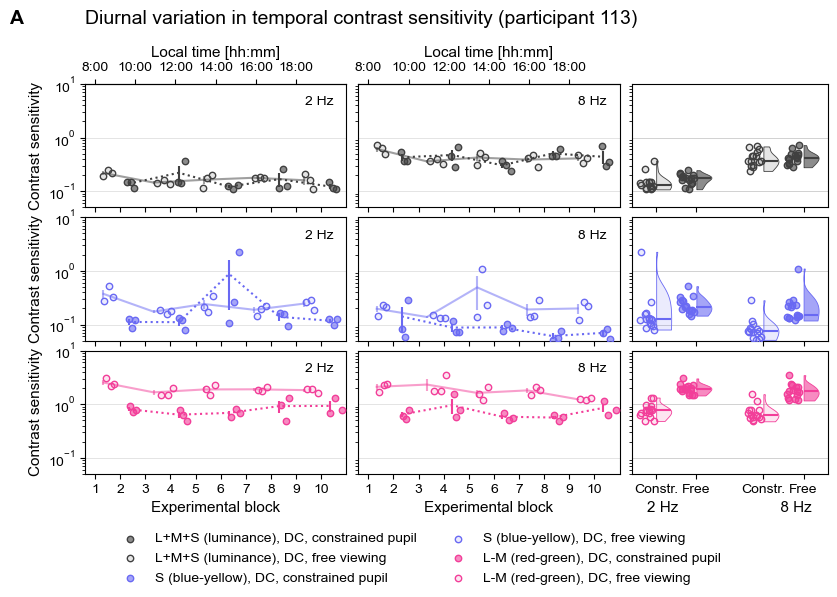

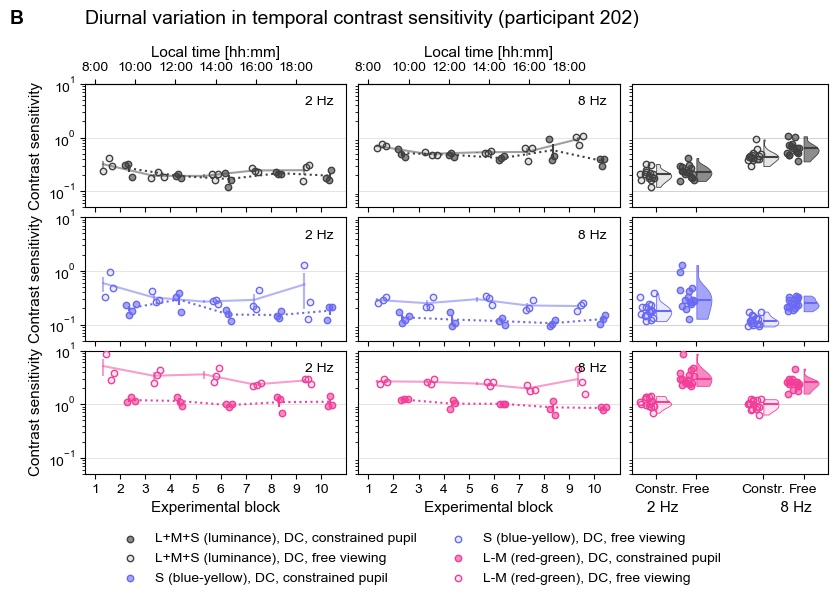

In [4]:
from pymetropsis.plotting import plot_metropsis_group
import pandas as pd

from pymetropsis.postcontrol import plot_diurnal_control 

data = pd.read_csv(RAW_DIR / "clean_metropsis_dc.csv")
data = data.loc[(data["participant_id"].notna())]
data["session"] = "DC"
# Create new column for context, C for constraint pupil, F for free viewing
data["context"] = "F"
# Set context to C for odd block numbers
data.loc[data["block"] % 2 == 1, "context"] = "C"
data["session_context"] = (data["session"] + "_" + data["context"]).str.lower()

# select participants that participant_id is not None
pid_df = data.loc[(data["participant_id"].notna())]  # corrected notnan() to notna()
mean_df = plot_metropsis_group.summarize_contrastsens_by(
    data=data,
    group_vars=[
        "participant_id",
        "session_context",
        "datetime_block",
        "hours_since_start_block",
        "block",
        "condition",
        "freq",
    ],
    cs_col="contrast_sensitivity",
)

# participant specific plots with 3 by 2 layout for each mechanism-frequency-combination
for i_pid, (pid, pid_df) in enumerate(data.groupby("participant_id")):
    fig, ax = plot_diurnal_control.sessionwise_timecourses_in_condition_frequency_plot(
        data=pid_df
    )
    fig.show()

(-0.529, 2.529)
(-0.5853136951118949, 2.531681604529138)


/var/folders/v4/b6y78y7s3l57mfm66yxz0qkr0000gp/T/ipykernel_66566/3650099623.py:220: UserWarning: Matplotlib is currently using module://matplotlib_inline.backend_inline, which is a non-GUI backend, so cannot show the figure.
  fig.show()


(-0.5315175478888121, 2.529119883232801)
(-0.529, 2.529)


/var/folders/v4/b6y78y7s3l57mfm66yxz0qkr0000gp/T/ipykernel_66566/3650099623.py:230: UserWarning: Matplotlib is currently using module://matplotlib_inline.backend_inline, which is a non-GUI backend, so cannot show the figure.
  fig.show()


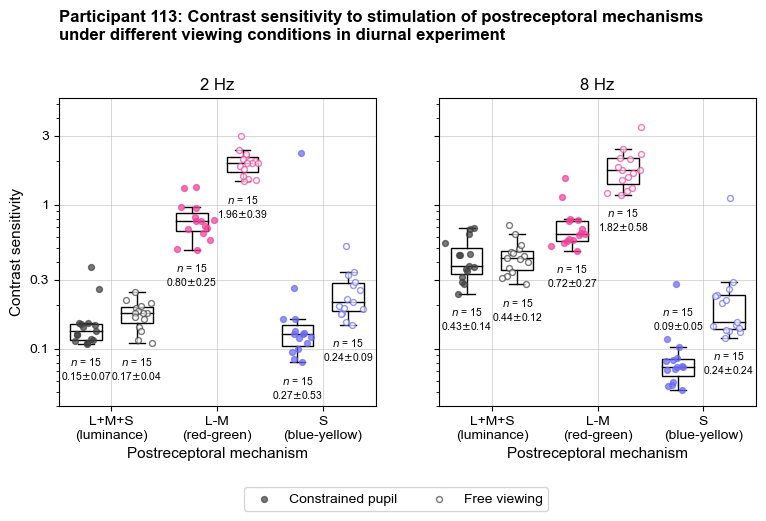

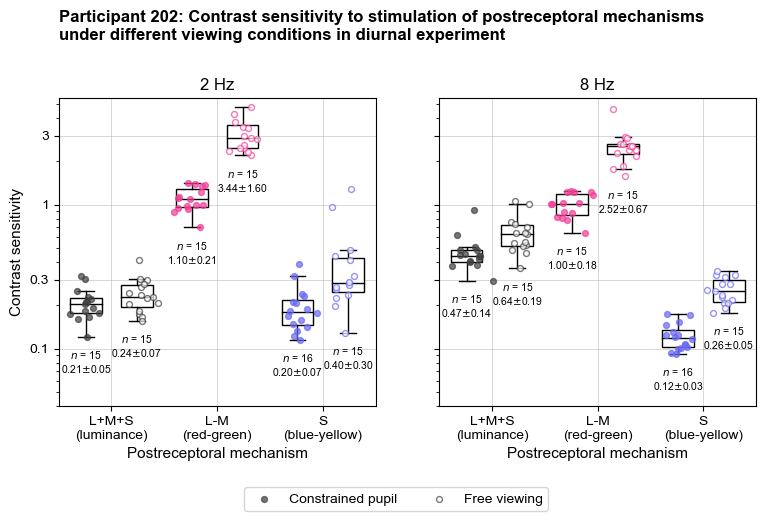

In [5]:
# Boxplots with rainclouds for each mechanism-context-combination
# 2 side-by-side panels for each frequency
# 2 by 3 plots for each mechanism-context-combination
# Boxplot with raincloud underneath

from matplotlib import pyplot as plt
import numpy as np
import matplotlib.patches as mpatches

from pymetropsis.plotting.plot_utils import save_figure

# Create a table with summary statistics for each participant, condition, frequency, and context
summary_stats = (
    data.groupby(
        [
            "participant_id",
            "condition",
            "freq",
            "session_context",
        ]  # group by these columns
    )
    .agg(
        mean_contrast=("contrast_sensitivity", "mean"),
        sem_contrast=("contrast_sensitivity", "sem"),
        count=("contrast_sensitivity", "count"),
    )
    .reset_index()
)


def boxplot_condition_and_viewcontext_by_freq(df_pid, annotate_stats=False):

    # desired order for conditions and freq panels
    condition_order = ["achromatic", "red-green", "blue-yellow"]
    condition_labels_order = ["L+M+S\n(luminance)", "L-M\n(red-green)", "S\n(blue-yellow)"]
    freq_order = sorted(df_pid["freq"].dropna().unique())  # expects [2, 8]
    context_order = sorted(df_pid["session_context"].unique())

    # colors for session_context
    condition_dict = {
                "achromatic": "L+M+S (luminance)",
                "red-green": "L-M (red-green)",
                "blue-yellow": "S (blue-yellow)",
            }
    context_dict = {
        "fd_c": "FD, constrained pupil",
        "dc_c": "Constrained pupil",  # Diurnal control,\nc
        "dc_f": "Free viewing",  # Diurnal control,\nfree viewing
    }
    context_map = {context_order[0]: "#66C2A5", context_order[1]: "#FC8D62"}
    colour_map = {
        "achromatic": "#404040",
        "blue-yellow": "#6969F3",
        "red-green": "#F23E99",
    }

    n_conditions = len(condition_order)
    x = np.arange(n_conditions)
    width = 0.30  # width of each box

    fig, axes = plt.subplots(1, len(freq_order), figsize=(9, 4), sharey=True)
    if len(freq_order) == 1:
        axes = [axes]

    for ax, freq in zip(axes, freq_order):
        # Collect data for each session and condition
        context_data = []
        for i_cont, context in enumerate(context_order):
            cont_list = []
            # Select colour condition
            for cond in condition_order:
                values = df_pid.loc[
                (df_pid["freq"] == freq)
                & (df_pid["session_context"] == context)
                & (df_pid["condition"] == cond),
                "contrast_sensitivity",
                ].values
                cont_list.append(values)

            context_data.append(cont_list)

            # Plot boxplots for each context# draw boxplots for each context with shifted positions
            select_data = context_data[i_cont]
            if i_cont == 0:
                positions = x - width / 1.25
            else:
                positions = x + width / 1.25

            # ensure each element is sequence (boxplot requires that)
            bp = ax.boxplot(
                select_data,
                positions=positions,
                widths=width,
                patch_artist=True,
                manage_ticks=False,
                showfliers=False,
                zorder=2,  # Set zorder to ensure boxplot is behind scatter dots
            )

            # style boxes
            for i_cond, patch in enumerate(bp["boxes"]):
                # set facecolor based on colour condition cond
                patch.set(
                    facecolor="#ffffffff", # colour_map[condition_order[i_cond]] + "33",
                    linewidth=1,
                    edgecolor="k",  # Set edge color to black
                )
            for element in ["whiskers", "caps", "medians"]:
                for art in bp[element]:
                    art.set(color="k")

            # overlay individual points (jittered)
            for i_cond, vals in enumerate(select_data):
                if len(vals) == 0:
                    continue
                xpos = positions[i_cond]
                jitter = np.random.normal(loc=xpos, scale=0.08, size=len(vals))
                condition_colour = (
                colour_map[condition_order[i_cond]] if i_cont == 0 else "#ffffffff"
                )
                scatter = ax.scatter(
                    jitter,
                    vals,
                    facecolor=condition_colour,
                    edgecolor=colour_map[condition_order[i_cond]],
                    alpha=0.7,
                    s=18,
                    linewidths=1,
                    zorder=3,
                    label=f"{context_dict[context]}" if condition_order[i_cond] == "achromatic" else None,
                )  # Set zorder to ensure scatter dots are in front

            # Annotate mean ± std below each box for this context
            if annotate_stats:
                for i_cond, vals in enumerate(select_data):
                    if len(vals) == 0:
                        continue
                    ntests = len(vals)
                    # choose y position below the lowest data point for that box
                    y_data_min = np.min(vals)
                    y_pos = y_data_min * 0.82  # bump below bottom
                    # If this goes beyond current ylim, expand it (log scale safe)
                    if y_pos < ax.get_ylim()[0]:
                        ax.set_ylim(y_pos * 0.93, ax.get_ylim()[1])
                    # if too low position bump above box above whisker position from boxplot
                    if np.mean(vals) < 0.1:
                        y_pos = 1.7 * (np.percentile(vals, 75) + 1.5 * (np.percentile(vals, 75) - np.percentile(vals, 25)))
                    ax.text(
                        positions[i_cond],
                        y_pos,
                        f"$n$ = {ntests}\n{np.mean(vals):.2f}$\pm${np.std(vals):.2f}",
                        ha="center",
                        va="top",
                        # bold font
                        # fontweight="bold",
                        fontsize=7.5,
                        zorder=4,
                    )

        # cosmetics
        ax.set_xticks(ticks=np.arange(len(condition_order)), labels=condition_labels_order)
        # ax.set_xticklabels(cond_order, rotation=0)

        ax.set_title(f"{freq} Hz")
        ax.set_yscale("log")
        ax.set_ylim(0.04, 5.5)
        ax.set_yticks([0.1, 0.3, 1, 3], [0.1, 0.3, 1, 3])
        if ax is axes[0]:
            ax.set_ylabel("Contrast sensitivity")
        print(ax.get_xlim())
        ax.set_xlim(-0.5, 2.5)
        ax.set_xlabel("Postreceptoral mechanism")

    # shared x-axis label
    # fig.supxlabel("Postreceptoral mechanism", fontsize=11, y=-0.07)

    # legend outside the plot
    handles, labels = ax.get_legend_handles_labels()
    unique_labels = dict(zip(labels, handles))  # Remove duplicates while preserving order
    fig.legend(
        unique_labels.values(),
        unique_labels.keys(),
        #title="Visual context",
        #title_fontproperties={"weight": "normal", "size": 10},
        loc="lower center",
        bbox_to_anchor=(0.5, -0.17),
        ncol=2,
        frameon=True,
    )

    # gridlines
    for ax in axes:
        ax.yaxis.grid(True, which="major", linestyle="-", linewidth=0.5, alpha=0.7)
        ax.xaxis.grid(True, which="major", linestyle="-", linewidth=0.5, alpha=0.7)
        # ax.yaxis.grid(True, which="minor", linestyle=":", linewidth=0.5, alpha=0.5)

    # Add figure title
    fig.suptitle(
        f"Participant {df['participant_id'].values[0]}: Contrast sensitivity to stimulation of postreceptoral mechanisms\nunder different viewing conditions in diurnal experiment",
        fontsize=12,
        fontweight="bold",
        y=1.1,
        ha="left",
        x=0.125,
    )
    return fig, axes


ensure_dir(FIG_DIR / "tcs")
# filter to participant 113
seed = 230459
pid = 113
df = data.loc[data["participant_id"] == pid].copy()
fig, axes = boxplot_condition_and_viewcontext_by_freq(df_pid=df, annotate_stats=True)
fig.savefig(
    fname=FIG_DIR / "tcs" / f"fig_diurnal_control_cs_{pid}.pdf",
    bbox_inches="tight",
    dpi=300,
)
fig.show()

pid = 202
df = data.loc[data["participant_id"] == pid].copy()
fig, axes = boxplot_condition_and_viewcontext_by_freq(df_pid=df, annotate_stats=True)
fig.savefig(
    fname=FIG_DIR / "tcs" / f"fig_diurnal_control_cs_{pid}.pdf",
    bbox_inches="tight",
    # dpi=300,
)
fig.show()

In [6]:
data = pd.read_csv(RAW_DIR / "clean_metropsis_dc.csv")
data = data.loc[(data["participant_id"].notna())]
data["session"] = "DC"
# Create new column for context, C for constraint pupil, F for free viewing
data["context"] = "F"
# Set context to C for odd block numbers
data.loc[data["block"] % 2 == 1, "context"] = "C"
data["session_context"] = (data["session"] + "_" + data["context"]).str.lower()



In [7]:
dc_participants = [113, 202]
dc = data.copy()
dc = dc.loc[dc["participant_id"].isin(dc_participants)]
dc.tail(10)

,Unnamed: 0,participant_id,datetime,condition,freq,thres,thres_sd,contrast_sensitivity,block,test,...,hours_since_start,hours_since_wakeup,hours_since_start_block,hours_since_wakeup_block,tcs,ln_tcs,log_tcs,session,context,session_context
352,352,202,2025-08-19 19:27:10,blue-yellow,2,4.715876,1.402658,0.212050,9.0,2,...,11.654722,12.654722,11.666667,12.666667,0.212050,-1.550935,-0.673562,DC,C,dc_c
353,353,202,2025-08-19 19:27:10,blue-yellow,8,8.028401,2.678456,0.124558,9.0,2,...,11.654722,12.654722,11.666667,12.666667,0.124558,-2.082985,-0.904629,DC,C,dc_c
354,354,202,2025-08-19 19:28:58,red-green,2,0.705490,0.156691,1.417454,9.0,2,...,11.684722,12.684722,11.666667,12.666667,1.417454,0.348862,0.151509,DC,C,dc_c
355,355,202,2025-08-19 19:28:58,red-green,8,1.282372,0.244824,0.779805,9.0,2,...,11.684722,12.684722,11.666667,12.666667,0.779805,-0.248711,-0.108014,DC,C,dc_c
356,356,202,2025-08-19 19:31:53,achromatic,2,4.000522,1.585305,0.249967,9.0,3,...,11.733333,12.733333,11.666667,12.666667,0.249967,-1.386425,-0.602117,DC,C,dc_c
357,357,202,2025-08-19 19:31:53,achromatic,8,2.522100,0.570683,0.396495,9.0,3,...,11.733333,12.733333,11.666667,12.666667,0.396495,-0.925092,-0.401762,DC,C,dc_c
358,358,202,2025-08-19 19:34:24,blue-yellow,2,4.797967,0.955373,0.208422,9.0,3,...,11.775278,12.775278,11.666667,12.666667,0.208422,-1.568192,-0.681057,DC,C,dc_c
359,359,202,2025-08-19 19:34:24,blue-yellow,8,6.579408,1.488741,0.151989,9.0,3,...,11.775278,12.775278,11.666667,12.666667,0.151989,-1.883945,-0.818187,DC,C,dc_c
360,360,202,2025-08-19 19:36:22,red-green,2,1.015735,0.332513,0.984509,9.0,3,...,11.808056,12.808056,11.666667,12.666667,0.984509,-0.015613,-0.006780,DC,C,dc_c
361,361,202,2025-08-19 19:36:22,red-green,8,1.142065,0.305569,0.875607,9.0,3,...,11.808056,12.808056,11.666667,12.666667,0.875607,-0.132838,-0.057691,DC,C,dc_c


In [8]:
fd = pd.read_csv(RAW_DIR / "clean_metropsis_TCS-2e.csv")
fd = fd.loc[(fd["participant_id"].notna())]
fd["session"] = "FD"
fd["context"] = "C"
fd["session_context"] = (fd["session"] + "_" + fd["context"]).str.lower()
# Filter to only include participants in dc_participants
dc_participants = [113, 202]
fd = fd.loc[fd["participant_id"].isin(dc_participants)]
fd.tail(20)

,Unnamed: 0,participant_id,datetime,condition,freq,thres,thres_sd,contrast_sensitivity,block,test,...,hours_since_start,hours_since_wakeup,hours_since_start_block,hours_since_wakeup_block,tcs,ln_tcs,log_tcs,session,context,session_context
366,382,202,2024-02-27 19:16:45,red-green,8.0,1.082273,0.157789,0.923982,9.0,3,...,36.407222,37.407222,35.00,36.00,0.923982,-0.079063,-0.034337,FD,C,fd_c
367,383,202,2024-02-27 19:16:45,red-green,2.0,1.023575,0.184120,0.976968,9.0,3,...,36.407222,37.407222,35.00,36.00,0.976968,-0.023301,-0.010120,FD,C,fd_c
368,384,202,2024-02-27 21:36:09,achromatic,8.0,2.565907,0.489491,0.389726,10.0,1,...,38.730556,39.730556,38.75,39.75,0.389726,-0.942312,-0.409241,FD,C,fd_c
369,385,202,2024-02-27 21:36:09,achromatic,2.0,6.815607,1.531778,0.146722,10.0,1,...,38.730556,39.730556,38.75,39.75,0.146722,-1.919215,-0.833505,FD,C,fd_c
370,386,202,2024-02-27 21:38:39,blue-yellow,8.0,6.768916,3.936946,0.147734,10.0,1,...,38.772222,39.772222,38.75,39.75,0.147734,-1.912341,-0.830519,FD,C,fd_c
371,387,202,2024-02-27 21:38:39,blue-yellow,2.0,3.041254,0.655136,0.328812,10.0,1,...,38.772222,39.772222,38.75,39.75,0.328812,-1.112270,-0.483053,FD,C,fd_c
372,388,202,2024-02-27 21:45:05,red-green,8.0,0.828135,0.088682,1.207533,10.0,1,...,38.879444,39.879444,38.75,39.75,1.207533,0.188579,0.081899,FD,C,fd_c
373,389,202,2024-02-27 21:45:05,red-green,2.0,0.826543,0.098145,1.209858,10.0,1,...,38.879444,39.879444,38.75,39.75,1.209858,0.190503,0.082734,FD,C,fd_c
374,390,202,2024-02-27 22:56:23,achromatic,8.0,2.157173,0.334504,0.463570,10.0,2,...,40.067778,41.067778,38.75,39.75,0.463570,-0.768799,-0.333885,FD,C,fd_c
375,391,202,2024-02-27 22:56:23,achromatic,2.0,4.841964,0.936581,0.206528,10.0,2,...,40.067778,41.067778,38.75,39.75,0.206528,-1.577320,-0.685022,FD,C,fd_c


In [9]:
import pandas as pd


# Build the combined frame from the raw files rather than from notebook state,
# so session/context labels cannot be lost by an out-of-order cell run.
def load_fd_dc(dc_participants=(113, 202)):
    """Concatenate the FD and DC sessions, labelling session and viewing context."""
    dc = pd.read_csv(RAW_DIR / "clean_metropsis_dc.csv")
    dc = dc.loc[dc["participant_id"].notna()].copy()
    dc["session"] = "DC"
    # C for constrained pupil (odd blocks), F for free viewing
    dc["context"] = "F"
    dc.loc[dc["block"] % 2 == 1, "context"] = "C"

    fd = pd.read_csv(RAW_DIR / "clean_metropsis_TCS-2e.csv")
    fd = fd.loc[fd["participant_id"].notna()].copy()
    fd["session"] = "FD"
    fd["context"] = "C"

    dc = dc.loc[dc["participant_id"].isin(dc_participants)]
    fd = fd.loc[fd["participant_id"].isin(dc_participants)]

    out = pd.concat([fd, dc], ignore_index=True)
    out["session_context"] = (out["session"] + "_" + out["context"]).str.lower()
    return out


df = load_fd_dc()
assert df["session_context"].notna().all(), "unlabelled rows in combined frame"
df.to_csv(DERIVATIVES_DIR / "metropsis_fd_dc.csv", index=False)
df["session_context"].value_counts()

session_context
fd_c    386
dc_c    182
dc_f    180
Name: count, dtype: int64

## Exploration


In [10]:
from pymetropsis.plotting.plot_metropsis_group import summarize_contrastsens_by

data = df.copy()
sumstat = summarize_contrastsens_by(
    data=data,
    group_vars=["participant_id", "session_context", "condition", "freq"],
    cs_col="contrast_sensitivity",
)
sumstat

,participant_id,session_context,condition,freq,cs_mean,cs_sem
0,113,dc_c,achromatic,2.0,0.154141,0.018232
1,113,dc_c,achromatic,8.0,0.430235,0.037047
2,113,dc_c,blue-yellow,2.0,0.271449,0.142776
3,113,dc_c,blue-yellow,8.0,0.089606,0.014573
4,113,dc_c,red-green,2.0,0.796157,0.065518
5,113,dc_c,red-green,8.0,0.718673,0.071438
6,113,dc_f,achromatic,2.0,0.173064,0.009699
7,113,dc_f,achromatic,8.0,0.439332,0.031010
8,113,dc_f,blue-yellow,2.0,0.244326,0.024896
9,113,dc_f,blue-yellow,8.0,0.243273,0.063271


In [11]:
# Create table with group by participant and freq, and then upper column header condition, and lower column header session_context
pt = sumstat.pivot(
    index=["participant_id", "freq"],
    columns=["condition", "session_context"],
    values="cs_mean",
).sort_index(axis=1)
pt.index.names = ['participant_id', 'freq'] 
pt.columns.names = ['condition', 'session_context']
pt

condition           achromatic                     blue-yellow            \
session_context           dc_c      dc_f      fd_c        dc_c      dc_f   
participant_id freq                                                        
113            2.0    0.154141  0.173064  0.161623    0.271449  0.244326   
               8.0    0.430235  0.439332  0.451292    0.089606  0.243273   
202            2.0    0.208294  0.239114  0.187852    0.195656  0.404584   
               8.0    0.470749  0.640036  0.423683    0.122570  0.256258   

condition                     red-green                      
session_context          fd_c      dc_c      dc_f      fd_c  
participant_id freq                                          
113            2.0   0.183272  0.796157  1.958151  1.157851  
               8.0   0.101575  0.718673  1.817354  0.947515  
202            2.0   0.160517  1.100524  3.438346  1.721963  
               8.0   0.120361  0.996445  2.517824  0.924418

In [12]:
# compute mean and std from raw values and format as strings
grp = (
    data.groupby(["participant_id", "freq", "condition", "session_context"])[
        "contrast_sensitivity"
    ]
    .agg(["mean", "std"])
    .reset_index()
)
grp["cs_str"] = grp.apply(
    lambda r: f"{r['mean']:.2f} ({np.nan_to_num(r['std'], 0.0):.2f})", axis=1
)

pt = grp.pivot(
    index=["participant_id", "freq"],
    columns=["condition", "session_context"],
    values="cs_str",
).sort_index(axis=1)
pt.index.names = ["participant_id", "freq"]
pt.columns.names = ["condition", "session_context"]
pt

condition             achromatic                            blue-yellow  \
session_context             dc_c         dc_f         fd_c         dc_c   
participant_id freq                                                       
113            2.0   0.15 (0.07)  0.17 (0.04)  0.16 (0.04)  0.27 (0.55)   
               8.0   0.43 (0.14)  0.44 (0.12)  0.45 (0.26)  0.09 (0.06)   
202            2.0   0.21 (0.05)  0.24 (0.07)  0.19 (0.05)  0.20 (0.07)   
               8.0   0.47 (0.14)  0.64 (0.19)  0.42 (0.11)  0.12 (0.03)   

condition                                        red-green               \
session_context             dc_f         fd_c         dc_c         dc_f   
participant_id freq                                                       
113            2.0   0.24 (0.10)  0.18 (0.12)  0.80 (0.25)  1.96 (0.41)   
               8.0   0.24 (0.25)  0.10 (0.04)  0.72 (0.28)  1.82 (0.60)   
202            2.0   0.40 (0.31)  0.16 (0.04)  1.10 (0.21)  3.44 (1.65)   
               8.0   0.26 (0.05)  0.12 (0.04)  1.00 (0.19)  2.52 (0.70)   

condition                         
session_context             fd_c  
participant_id freq               
113            2.0   1.16 (0.71)  
               8.0   0.95 (0.52)  
202            2.0   1.72 (1.79)  
               8.0   0.92 (0.16)

In [13]:
# Format table by renaming dc_c into "constrained pupil" and dc_f into "free viewing", and
# changing condition names to more descriptive ones
condition_rename = {
    "achromatic": "L+M+S (luminance)",
    "red-green": "L-M (red-green)",
    "blue-yellow": "S (blue-yellow)",
}
context_rename = {
    "dc_c": "Constrained pupil",
    "dc_f": "Free viewing", 
    "fd_c": "FD / Constrained pupil",
}

# When using level=0/1 the function receives the label of that level (a string), not a tuple.
# Use the label directly for lookup in the rename dicts.
pt.rename(columns=lambda lvl: condition_rename[lvl], level=0, inplace=True)
pt.rename(columns=lambda lvl: context_rename[lvl], level=1, inplace=True)
pt

# Remove "condition" and change freq to "Temporal frequency (Hz)" in column names, and participant_id to "Participant ID" in index names
pt.index.rename({"participant_id": "Participant ID", "freq": "Temporal frequency (Hz)"}, inplace=True)
# For MultiIndex column level names, set_names requires a list-like; use set_names to clear them
pt.columns.set_names([None, None], inplace=True)


output_path = TABLE_DIR / "diurnal_control_cs_summary.csv"
ensure_dir(TABLE_DIR)
pt.to_csv(output_path)
pt

L+M+S (luminance)               \
                                       Constrained pupil Free viewing   
Participant ID Temporal frequency (Hz)                                  
113            2.0                           0.15 (0.07)  0.17 (0.04)   
               8.0                           0.43 (0.14)  0.44 (0.12)   
202            2.0                           0.21 (0.05)  0.24 (0.07)   
               8.0                           0.47 (0.14)  0.64 (0.19)   

                                                               \
                                       FD / Constrained pupil   
Participant ID Temporal frequency (Hz)                          
113            2.0                                0.16 (0.04)   
               8.0                                0.45 (0.26)   
202            2.0                                0.19 (0.05)   
               8.0                                0.42 (0.11)   

                                         S (blue-yellow)               \
                                       Constrained pupil Free viewing   
Participant ID Temporal frequency (Hz)                                  
113            2.0                           0.27 (0.55)  0.24 (0.10)   
               8.0                           0.09 (0.06)  0.24 (0.25)   
202            2.0                           0.20 (0.07)  0.40 (0.31)   
               8.0                           0.12 (0.03)  0.26 (0.05)   

                                                               \
                                       FD / Constrained pupil   
Participant ID Temporal frequency (Hz)                          
113            2.0                                0.18 (0.12)   
               8.0                                0.10 (0.04)   
202            2.0                                0.16 (0.04)   
               8.0                                0.12 (0.04)   

                                         L-M (red-green)               \
                                       Constrained pupil Free viewing   
Participant ID Temporal frequency (Hz)                                  
113            2.0                           0.80 (0.25)  1.96 (0.41)   
               8.0                           0.72 (0.28)  1.82 (0.60)   
202            2.0                           1.10 (0.21)  3.44 (1.65)   
               8.0                           1.00 (0.19)  2.52 (0.70)   

                                                               
                                       FD / Constrained pupil  
Participant ID Temporal frequency (Hz)                         
113            2.0                                1.16 (0.71)  
               8.0                                0.95 (0.52)  
202            2.0                                1.72 (1.79)  
               8.0                                0.92 (0.16)

## Plotting FD and DC in one


/var/folders/v4/b6y78y7s3l57mfm66yxz0qkr0000gp/T/ipykernel_66566/946321950.py:183: UserWarning: Matplotlib is currently using module://matplotlib_inline.backend_inline, which is a non-GUI backend, so cannot show the figure.
  fig.show()


0      2024-01-01 09:15:00
1      2024-01-01 09:15:00
2      2024-01-01 09:18:48
3      2024-01-01 09:18:48
4      2024-01-01 09:24:34
              ...         
743    2024-01-01 19:44:00
744    2024-01-01 19:46:31
745    2024-01-01 19:46:31
746    2024-01-01 19:48:29
747    2024-01-01 19:48:29
Name: datetime_standard, Length: 748, dtype: object

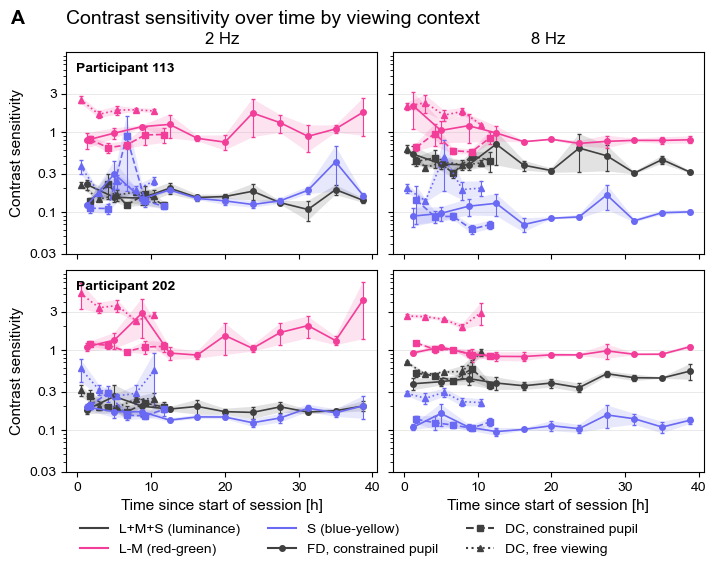

In [14]:
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.lines import Line2D

from pymetropsis.plotting.plot_metropsis_group import summarize_contrastsens_by

CONDITION_DICT = {
    "achromatic": "L+M+S (luminance)",
    "red-green": "L-M (red-green)",
    "blue-yellow": "S (blue-yellow)",
}
COLOUR_DICT = {
    "achromatic": "#404040",
    "blue-yellow": "#6969F3",
    "red-green": "#F23E99",
}
CONTEXT_DICT = {
    "fd_c": "FD, constrained pupil",
    "dc_c": "DC, constrained pupil",
    "dc_f": "DC, free viewing",
}
CONTEXT_STYLE = {"fd_c": "-", "dc_c": "--", "dc_f": ":"}
CONTEXT_MARKER = {"fd_c": "o", "dc_c": "s", "dc_f": "^"}


def plot_sessioncontext_mean(ax, data, x_col):
    """Draw one line per condition x session_context on a single Axes.

    Colour encodes the postreceptoral condition, linestyle and marker encode the
    session and viewing context.
    """
    for cond, cond_data in data.groupby("condition"):
        for context, df_line in cond_data.groupby("session_context"):
            df_line = df_line.sort_values(x_col)
            ax.fill_between(
                x=df_line[x_col],
                y1=df_line["cs_mean"] - df_line["cs_sem"],
                y2=df_line["cs_mean"] + df_line["cs_sem"],
                facecolor=COLOUR_DICT[cond],
                alpha=0.15,
                edgecolor="none",
            )
            ax.errorbar(
                x=df_line[x_col],
                y=df_line["cs_mean"],
                yerr=df_line["cs_sem"],
                marker=CONTEXT_MARKER[context],
                markersize=4,
                linestyle=CONTEXT_STYLE[context],
                linewidth=1.2,
                c=COLOUR_DICT[cond],
                elinewidth=0.8,
                capsize=1.5,
            )


def _legend_handles(data):
    """Two-part legend: colour marks condition, linestyle/marker marks context."""
    conditions = [c for c in CONDITION_DICT if c in set(data["condition"])]
    contexts = [c for c in CONTEXT_DICT if c in set(data["session_context"])]

    handles = [
        Line2D([], [], color=COLOUR_DICT[c], linestyle="-", label=CONDITION_DICT[c])
        for c in conditions
    ]
    handles += [
        Line2D(
            [],
            [],
            color="#404040",
            linestyle=CONTEXT_STYLE[c],
            marker=CONTEXT_MARKER[c],
            markersize=4,
            label=CONTEXT_DICT[c],
        )
        for c in contexts
    ]
    return handles, len(conditions)


def create_plot_blocktime_group_timecourses(
    data, x_col="hours_since_start_block", letter="A"
):
    """Create a figure with a plot grid of time courses for individuals (rows) and frequencies (columns)."""
    # Requires data that is already averaged per participant
    data = data.sort_values(by=["participant_id", x_col]).copy()
    pids = sorted(data["participant_id"].unique())
    freqs = sorted(data["freq"].unique())

    distance_left_edge = 0.11
    distance_right_edge = 0.04
    distance_top_edge = 0.14
    distance_bottom_edge = 0.16

    fig, axs = plt.subplots(
        nrows=len(pids),
        ncols=len(freqs),
        figsize=(7.5, 6),
        sharex=True,
        sharey=True,
        squeeze=False,
        gridspec_kw={
            "wspace": 0.05,
            "hspace": 0.08,
            "left": distance_left_edge,
            "right": (1 - distance_right_edge),
            "top": (1 - distance_top_edge),
            "bottom": distance_bottom_edge,
        },
    )

    for i_pid, pid in enumerate(pids):
        for i_freq, freq in enumerate(freqs):
            ax = axs[i_pid, i_freq]
            sel = data[(data["participant_id"] == pid) & (data["freq"] == freq)]
            plot_sessioncontext_mean(ax=ax, data=sel, x_col=x_col)

            ax.set_yscale("log")
            ax.set_ylim(0.03, 10)
            ax.set_yticks([0.03, 0.1, 0.3, 1, 3], [0.03, 0.1, 0.3, 1, 3])
            ax.yaxis.grid(True, which="major", linewidth=0.4, alpha=0.5)

            # Panel identity: participant on the left, frequency on top
            if i_freq == 0:
                ax.set_ylabel("Contrast sensitivity")
                ax.annotate(
                    text=f"Participant {int(pid)}",
                    xy=(0.03, 0.9),
                    xycoords="axes fraction",
                    fontweight="bold",
                )
            if i_pid == 0:
                ax.set_title(f"{int(freq)} Hz")
            if i_pid == len(pids) - 1:
                ax.set_xlabel("Time since start of session [h]")

    handles, n_cond = _legend_handles(data)
    fig.legend(
        handles=handles,
        ncol=n_cond,
        loc="lower center",
        bbox_to_anchor=(0.5, 0.0),
        frameon=False,
    )

    fig.text(
        x=distance_left_edge * 1 / 3,
        y=(1 - distance_top_edge) + (distance_top_edge * 1 / 3),
        s=letter,
        transform=fig.transFigure,
        fontsize=14,
        fontweight="bold",
        ha="left",
    )
    fig.text(
        x=distance_left_edge,
        y=(1 - distance_top_edge) + (distance_top_edge * 1 / 3),
        s="Contrast sensitivity over time by viewing context",
        transform=fig.transFigure,
        fontsize=14,
        ha="left",
    )

    return fig, axs


data = pd.read_csv(DERIVATIVES_DIR / "metropsis_fd_dc.csv")

mean_df = summarize_contrastsens_by(
    data=data,
    group_vars=[
        "participant_id",
        "session_context",
        "hours_since_start_block",
        "block",
        "condition",
        "freq",
    ],
    cs_col="contrast_sensitivity",
)

fig, _ = create_plot_blocktime_group_timecourses(data=mean_df)
fig.show()
data.datetime_standard

## Plotting FD and DC by time of day

Same data plotted against clock time (`datetime_standard`) rather than time since
session start, restricted to 08:00-22:00. Each postreceptoral condition gets its
own block of columns (one per temporal frequency), so the conditions no longer
overplot each other.

FD spans two calendar days that overlap in clock time, so the two days are kept
as separate series instead of being averaged onto a single hour-of-day axis.

/var/folders/v4/b6y78y7s3l57mfm66yxz0qkr0000gp/T/ipykernel_66566/3585616681.py:282: UserWarning: Matplotlib is currently using module://matplotlib_inline.backend_inline, which is a non-GUI backend, so cannot show the figure.
  fig.show()
/var/folders/v4/b6y78y7s3l57mfm66yxz0qkr0000gp/T/ipykernel_66566/3585616681.py:284: UserWarning: Matplotlib is currently using module://matplotlib_inline.backend_inline, which is a non-GUI backend, so cannot show the figure.
  fig.show()


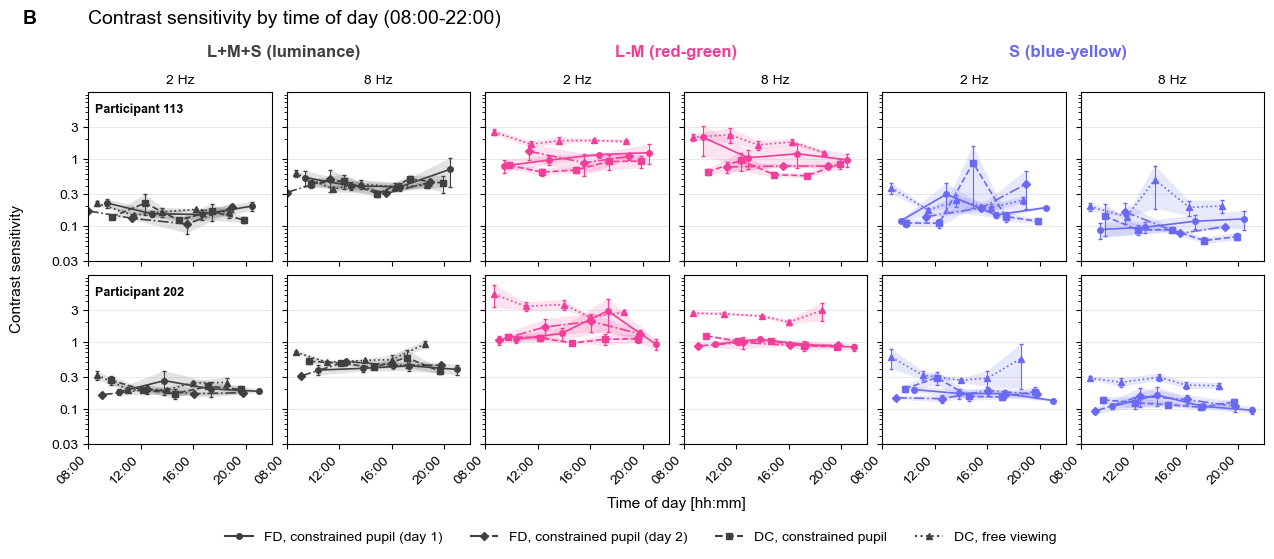

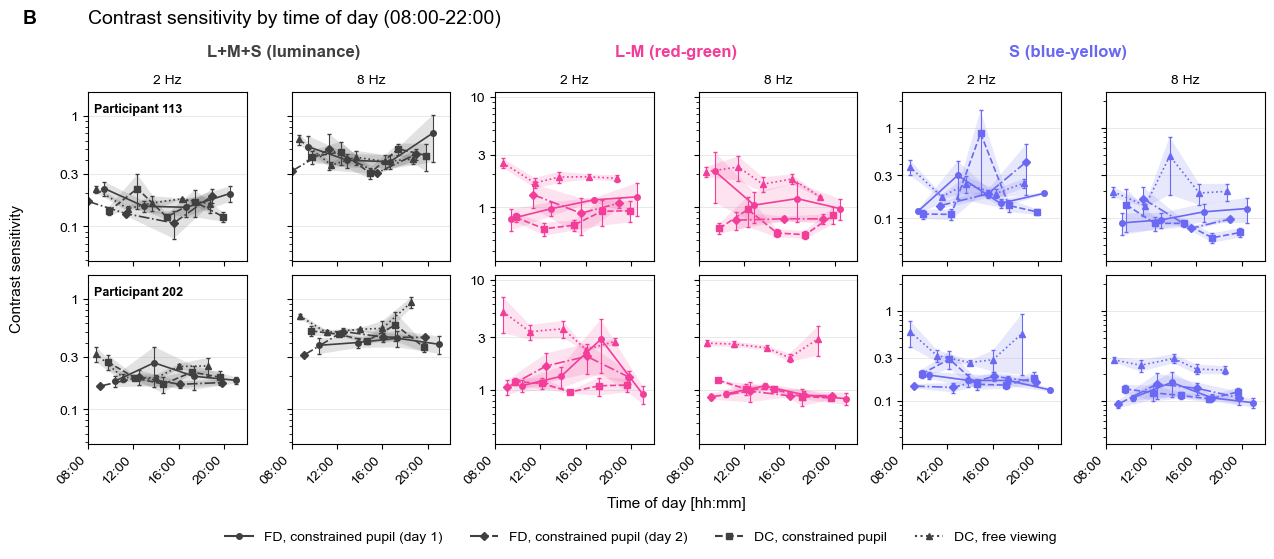

In [15]:
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter

from pymetropsis.plotting.plot_metropsis_group import summarize_contrastsens_by

# FD spans two calendar days that overlap in clock time, so day 1 and day 2 are
# kept as separate series rather than averaged onto one hour-of-day axis.
SERIES_DICT = {
    "fd_c_d1": "FD, constrained pupil (day 1)",
    "fd_c_d2": "FD, constrained pupil (day 2)",
    "dc_c": "DC, constrained pupil",
    "dc_f": "DC, free viewing",
}
SERIES_STYLE = {"fd_c_d1": "-", "fd_c_d2": "-.", "dc_c": "--", "dc_f": ":"}
SERIES_MARKER = {"fd_c_d1": "o", "fd_c_d2": "D", "dc_c": "s", "dc_f": "^"}

DAY_START_HOUR = 8
DAY_END_HOUR = 22
CONDITION_ORDER = ["achromatic", "red-green", "blue-yellow"]

YLIM_SHARED = (0.03, 10)
YTICKS_SHARED = [0.03, 0.1, 0.3, 1, 3]
# Candidate ticks; only those inside a panel's limits are drawn
YTICKS_DENSE = [0.03, 0.1, 0.3, 1, 3, 10]


def add_clocktime(data):
    """Add hour-of-day from datetime_standard and a series key separating FD days."""
    out = data.copy()
    ts = pd.to_datetime(out["datetime_standard"])
    out["hour_of_day"] = ts.dt.hour + ts.dt.minute / 60 + ts.dt.second / 3600

    day_index = ts.dt.normalize().rank(method="dense").astype(int)
    out["series"] = out["session_context"]
    is_fd = out["session_context"] == "fd_c"
    out.loc[is_fd, "series"] = "fd_c_d" + day_index[is_fd].astype(str)
    return out


def select_daytime(data, start=DAY_START_HOUR, end=DAY_END_HOUR):
    """Keep only tests recorded between `start` and `end` o'clock."""
    return data[(data["hour_of_day"] >= start) & (data["hour_of_day"] <= end)]


def _hhmm(x, _pos=None):
    hours = int(x)
    minutes = int(round((x - hours) * 60))
    return f"{hours:02d}:{minutes:02d}"


def _condition_ylim(data, cond, pad=1.6):
    """Y limits covering one condition's mean +/- sem across all its panels."""
    sel = data[data["condition"] == cond]
    low = (sel["cs_mean"] - sel["cs_sem"]).min()
    high = (sel["cs_mean"] + sel["cs_sem"]).max()
    return low / pad, high * pad


def _series_legend_handles(data):
    """Legend only needs the session/context styles; colour is labelled per condition."""
    series = [s for s in SERIES_DICT if s in set(data["series"])]
    return [
        Line2D(
            [],
            [],
            color="#404040",
            linestyle=SERIES_STYLE[s],
            marker=SERIES_MARKER[s],
            markersize=4,
            label=SERIES_DICT[s],
        )
        for s in series
    ]


def plot_series_mean(ax, data, x_col):
    """Colour encodes condition, linestyle and marker encode session/day/context."""
    for cond, cond_data in data.groupby("condition"):
        for series, df_line in cond_data.groupby("series"):
            df_line = df_line.sort_values(x_col)
            ax.fill_between(
                x=df_line[x_col],
                y1=df_line["cs_mean"] - df_line["cs_sem"],
                y2=df_line["cs_mean"] + df_line["cs_sem"],
                facecolor=COLOUR_DICT[cond],
                alpha=0.15,
                edgecolor="none",
            )
            ax.errorbar(
                x=df_line[x_col],
                y=df_line["cs_mean"],
                yerr=df_line["cs_sem"],
                marker=SERIES_MARKER[series],
                markersize=4,
                linestyle=SERIES_STYLE[series],
                linewidth=1.2,
                c=COLOUR_DICT[cond],
                elinewidth=0.8,
                capsize=1.5,
            )


def create_plot_clocktime_timecourses(
    data, x_col="hour_of_day_block", letter="B", sharey=True
):
    """Grid of clock-time courses: participants (rows) by condition x frequency (columns).

    Each condition gets its own block of columns, one per temporal frequency, so
    the conditions no longer overplot each other on shared axes.

    Args:
        sharey: If True, every panel uses one common y scale, so sensitivity is
            comparable across conditions. If False, each condition gets its own
            y scale fitted to its data, which shows within-condition structure
            but makes cross-condition magnitudes non-comparable.
    """
    data = data.sort_values(by=["participant_id", x_col]).copy()
    pids = sorted(data["participant_id"].unique())
    freqs = sorted(data["freq"].unique())
    conditions = [c for c in CONDITION_ORDER if c in set(data["condition"])]

    # Columns are condition-major: each condition contributes one column per frequency
    col_keys = [(cond, freq) for cond in conditions for freq in freqs]

    left, right, top, bottom = 0.075, 0.02, 0.16, 0.20
    # Independent y scales need room for tick labels on each condition block
    wspace = 0.08 if sharey else 0.28

    fig, axs = plt.subplots(
        nrows=len(pids),
        ncols=len(col_keys),
        figsize=(13, 5.5),
        sharex=True,
        # When scales are per-condition, limits are set explicitly per panel
        # instead of being linked across every column
        sharey=sharey,
        squeeze=False,
        gridspec_kw={
            "wspace": wspace,
            "hspace": 0.08,
            "left": left,
            "right": 1 - right,
            "top": 1 - top,
            "bottom": bottom,
        },
    )

    cond_ylim = {} if sharey else {c: _condition_ylim(data, c) for c in conditions}

    for i_pid, pid in enumerate(pids):
        for i_col, (cond, freq) in enumerate(col_keys):
            ax = axs[i_pid, i_col]
            sel = data[
                (data["participant_id"] == pid)
                & (data["freq"] == freq)
                & (data["condition"] == cond)
            ]
            plot_series_mean(ax=ax, data=sel, x_col=x_col)

            ax.set_yscale("log")
            if sharey:
                ax.set_ylim(*YLIM_SHARED)
                ax.set_yticks(YTICKS_SHARED, YTICKS_SHARED)
            else:
                low, high = cond_ylim[cond]
                ax.set_ylim(low, high)
                ticks = [t for t in YTICKS_DENSE if low <= t <= high]
                ax.set_yticks(ticks, ticks)
            ax.yaxis.grid(True, which="major", linewidth=0.4, alpha=0.5)

            ax.set_xlim(DAY_START_HOUR, DAY_END_HOUR)
            ax.set_xticks([8, 12, 16, 20])
            ax.xaxis.set_major_formatter(FuncFormatter(_hhmm))

            # With independent scales each condition block needs its own tick labels
            first_of_block = (i_col % len(freqs)) == 0
            show_yticks = (i_col == 0) if sharey else first_of_block
            if not show_yticks:
                ax.tick_params(axis="y", labelleft=False)

            if i_col == 0:
                ax.annotate(
                    text=f"Participant {int(pid)}",
                    xy=(0.04, 0.88),
                    xycoords="axes fraction",
                    fontweight="bold",
                    fontsize=9,
                )
            if i_pid == 0:
                ax.set_title(f"{int(freq)} Hz", fontsize=10)
            if i_pid == len(pids) - 1:
                ax.tick_params(axis="x", rotation=45)
                for tick in ax.get_xticklabels():
                    tick.set_horizontalalignment("right")

    # Condition banner spanning that condition's frequency columns
    plot_width = 1 - left - right
    col_width = plot_width / len(col_keys)
    for i_cond, cond in enumerate(conditions):
        centre = left + (i_cond * len(freqs) + len(freqs) / 2) * col_width
        fig.text(
            x=centre,
            y=(1 - top) + 0.065,
            s=CONDITION_DICT[cond],
            ha="center",
            fontsize=12,
            fontweight="bold",
            color=COLOUR_DICT[cond],
        )

    # One shared x label, so it is not repeated once per column
    fig.text(
        x=left + plot_width / 2,
        y=bottom - 0.115,
        s="Time of day [hh:mm]",
        ha="center",
        fontsize=plt.rcParams["axes.labelsize"],
    )
    # One shared y label, so it is not repeated once per condition block
    fig.text(
        x=left / 5,
        y=bottom + (1 - top - bottom) / 2,
        s="Contrast sensitivity",
        va="center",
        rotation="vertical",
        fontsize=plt.rcParams["axes.labelsize"],
    )

    fig.legend(
        handles=_series_legend_handles(data),
        ncol=4,
        loc="upper center",
        bbox_to_anchor=(0.5, bottom - 0.135),
        frameon=False,
    )
    fig.text(
        x=left / 3,
        y=(1 - top) + 0.125,
        s=letter,
        transform=fig.transFigure,
        fontsize=14,
        fontweight="bold",
        ha="left",
    )
    fig.text(
        x=left,
        y=(1 - top) + 0.125,
        s="Contrast sensitivity by time of day (08:00-22:00)",
        transform=fig.transFigure,
        fontsize=14,
        ha="left",
    )
    return fig, axs


clock_data = pd.read_csv(DERIVATIVES_DIR / "metropsis_fd_dc.csv")
clock_data = add_clocktime(clock_data)
clock_data = select_daytime(clock_data)

# Average within block, carrying the block's mean clock time as the x position
clock_data["hour_of_day_block"] = clock_data.groupby(
    ["participant_id", "series", "block"]
)["hour_of_day"].transform("mean")

clock_mean_df = summarize_contrastsens_by(
    data=clock_data,
    group_vars=[
        "participant_id",
        "series",
        "hour_of_day_block",
        "block",
        "condition",
        "freq",
    ],
    cs_col="contrast_sensitivity",
)

# sharey=False gives each condition its own y scale
fig, _ = create_plot_clocktime_timecourses(data=clock_mean_df, sharey=True)
fig.show()
fig, _ = create_plot_clocktime_timecourses(data=clock_mean_df, sharey=False)
fig.show()